# Étape 1 – Exploration du dataset

Ce notebook regarde les données **après** le nouveau split (`python src/split_data.py`).
Il répond à trois questions simples :

1. Combien d'images a-t-on par classe, dans chaque split ?
2. À quoi ressemblent les radios NORMAL et PNEUMONIA ?
3. Quelle taille et quel format ont les images d'origine ?

Les deux figures sont sauvegardées dans `reports/figures/` pour le rapport.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

# Le notebook est dans notebooks/ : on ajoute src/ au chemin pour pouvoir importer config.py
RACINE = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.append(str(RACINE / "src"))
from config import DATA_DIR, FIG_DIR, CLASSES, SEED

FIG_DIR.mkdir(parents=True, exist_ok=True)
SPLITS = ["train", "val", "test"]
COULEURS = {"NORMAL": "#2a78d6", "PNEUMONIA": "#eb6834"}  # une couleur fixe par classe

## 1. Combien d'images par classe ?

On compte simplement les fichiers de chaque dossier `data/processed/<split>/<classe>/`.

In [2]:
comptes = pd.DataFrame(
    {c: [len(list((DATA_DIR / s / c).glob("*"))) for s in SPLITS] for c in CLASSES},
    index=SPLITS)
comptes["Total"] = comptes.sum(axis=1)
comptes["% PNEUMONIA"] = (100 * comptes["PNEUMONIA"] / comptes["Total"]).round(1)
comptes

,NORMAL,PNEUMONIA,Total,% PNEUMONIA
train,1147,3300,4447,74.2
val,202,583,785,74.3
test,234,390,624,62.5


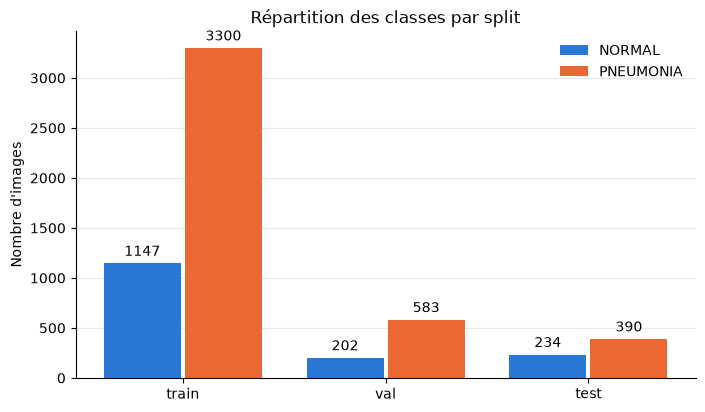

In [3]:
fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(len(SPLITS))          # position de chaque split sur l'axe horizontal
largeur = 0.38                      # largeur d'une barre

for i, c in enumerate(CLASSES):
    # (i - 0.5) décale la barre NORMAL à gauche et la barre PNEUMONIA à droite
    barres = ax.bar(x + (i - 0.5) * (largeur + 0.02), comptes[c], largeur,
                    label=c, color=COULEURS[c])
    ax.bar_label(barres, padding=3)  # effectif écrit au-dessus de chaque barre

ax.set_xticks(x, SPLITS)
ax.set_ylabel("Nombre d'images")
ax.set_title("Répartition des classes par split")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
ax.legend(frameon=False)

fig.savefig(FIG_DIR / "repartition_classes.png", dpi=150, bbox_inches="tight")
plt.show()

## 2. À quoi ressemblent les radios ?

On tire 8 images au hasard par classe dans le train. Le tirage utilise la seed du projet :
on obtient donc toujours les mêmes images.

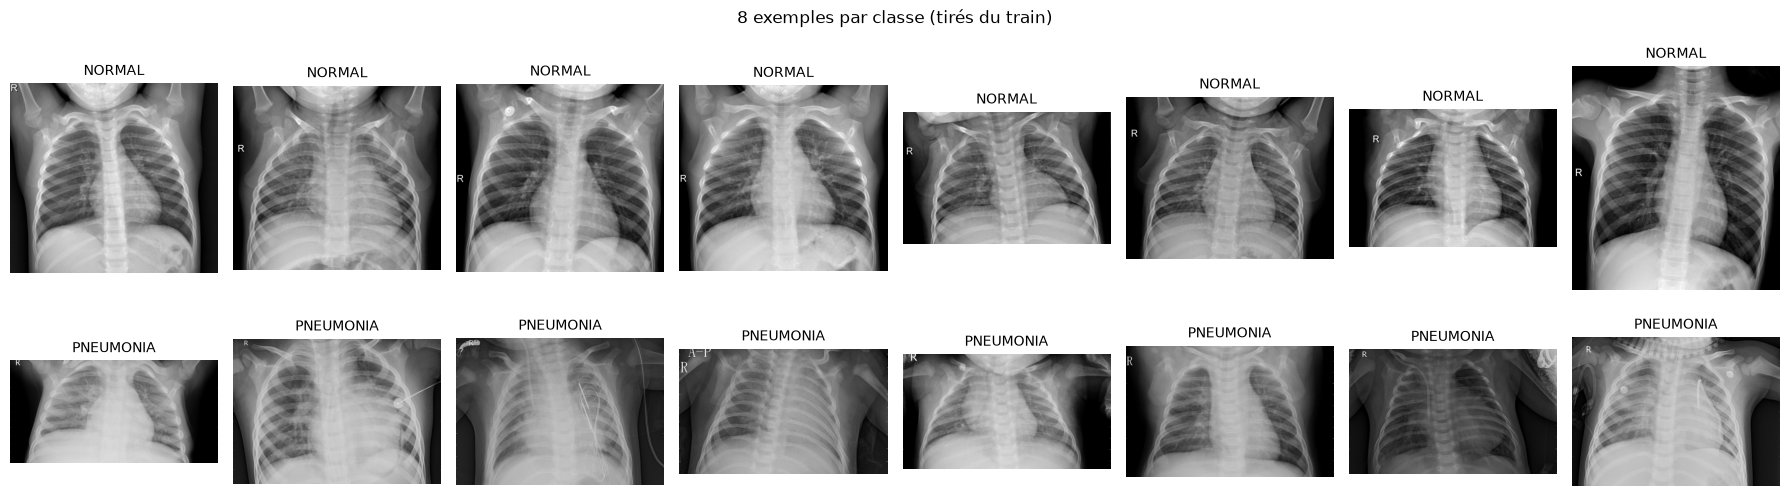

In [4]:
rng = np.random.default_rng(SEED)   # générateur aléatoire reproductible

fig, axes = plt.subplots(2, 8, figsize=(18, 5.6))
for ligne, c in enumerate(CLASSES):
    fichiers = sorted((DATA_DIR / "train" / c).glob("*"))
    choisis = rng.choice(len(fichiers), size=8, replace=False)   # 8 indices différents
    for ax, i in zip(axes[ligne], choisis):
        ax.imshow(Image.open(fichiers[i]), cmap="gray")
        ax.set_title(c, fontsize=10)
        ax.axis("off")

fig.suptitle("8 exemples par classe (tirés du train)")
fig.tight_layout()
fig.savefig(FIG_DIR / "exemples_radios.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Taille et format des images d'origine

On ouvre un échantillon de 300 images du train pour lire leurs dimensions et leur mode de couleur
(`L` = niveaux de gris, `RGB` = couleur).

In [5]:
fichiers = sorted((DATA_DIR / "train").glob("*/*"))
n = min(300, len(fichiers))
echantillon = [fichiers[i] for i in rng.choice(len(fichiers), size=n, replace=False)]

infos = []
for p in echantillon:
    with Image.open(p) as img:
        infos.append({"largeur": img.width, "hauteur": img.height, "mode": img.mode})
infos = pd.DataFrame(infos)

print(infos["mode"].value_counts().to_string())
infos[["largeur", "hauteur"]].describe().loc[["min", "50%", "max"]].round(0)

mode
L      286
RGB     14


,largeur,hauteur
min,450.0,234.0
50%,1272.0,888.0
max,2619.0,2628.0


## Ce qu'il faut retenir

- **Les classes sont déséquilibrées.** Dans le train, 74 % des images sont des pneumonies (environ 2,9 pneumonies pour 1 radio normale). Un modèle qui répondrait toujours « pneumonie » aurait déjà 74 % d'accuracy : il faudra des poids de classes (étape 2) et des métriques comme le recall, le F1 et l'AUC.
- **La stratification a fonctionné.** Train et val ont la même proportion de pneumonies (74,2 % et 74,3 %).
- **Le test est différent.** Il ne contient que 62,5 % de pneumonies. On n'y touche pas, mais il faudra s'en souvenir en comparant les scores de validation et de test.
- **Les images ont des tailles très variées** (de 450×234 à 2619×2628 pixels dans l'échantillon) : elles devront toutes être redimensionnées en 224×224.
- **Presque toutes sont en niveaux de gris** (mode `L`), quelques-unes en `RGB` : on les convertira toutes en 3 canaux, comme l'attendent les modèles ImageNet.
- **À l'œil**, les radios PNEUMONIA montrent souvent des zones plus blanches et voilées dans les poumons, mais la différence n'est pas toujours évidente : c'est justement ce que le modèle devra apprendre.